# Lab 08: Graphs, latent variables, and what the survey didn't keep

**ASTR 457, Fall 2026, posted Thu Oct 29, due Wed Nov 4 by noon (fork → PR, as always)**

This week we wrote graphs as `PyMC` code, and put a detector into the likelihood. You're going to do both, on your own midterm supernovae, on a survey that rejects everything below a threshold, and on one real Type Ia supernova observed in six bands.

Put your notebook in `submissions/<your netid>/lab08.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 35%, Part 2 30%, Part 3 25%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az

NETID = 'siyaoxu2'   # <-- set this
LAB = '../../labs/08/data/'                              # from submissions/<your netid>/
MIDTERM = f'../../labs/midterm/data/{NETID}/'

## Part 1: Your midterm, as a graph (35%)

On the midterm you fit the Tripp relation to your 250 supernovae (`p2_pantheon_sne.csv` in your midterm data folder):

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10).$$

In the posted solution's 2e simulation, the 68% interval on $\beta$ contained the true $\beta$ in only **6%** of 200 fake datasets! The other four parameters covered the truth 62-66% of the time. The solution blamed attenuation. You're going to draw the graph that shows where it comes from, build the model that removes it, and check that it does.

1. Draw the probabilistic graphical model of your midterm fit (your 2b likelihood), using the same key as Day 18 - parameters you fit as blue circles, latent (unobserved) values as white circles, data as grey circles, fixed quantities as dots, and a plate over supernovae. Draw it by hand (a photo is fine) or with any drawing tool, and put the image in your notebook. Then draw the graph of how the data were actually made. Each supernova has a *true* stretch $x_{1,i}$ and a *true* color $c_i$, drawn from a population (a mean and a width for each), and the catalog's $\hat m_{B,i}$, $\hat x_{1,i}$, $\hat c_i$ are noisy measurements of the true values, with that supernova's $3\times3$ covariance $C_i$. Which arrows does the midterm's graph lack, and which circle did it shade grey that should be white?
2. Fit the second graph in `PyMC`, with latent `x1_true` and `c_true` (one per supernova, `shape=N`), a mean and a width for each population, and the three observed quantities together in a `pm.MvNormal` with each $C_i$. Add $\sigma_{\rm int}^2$ and the peculiar-velocity variance to the $m_B$ term only. Handle the contaminants as you did on the midterm, and explain how. Pick centered or non-centered by Day 19's rule (compare the measurement errors with the population widths), and justify your choice. Report the largest $\hat R$, the smallest bulk effective sample size (the latent values included) and the number of divergences, then $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 68% intervals, in a table next to your midterm values.
3. Rerun the solution's 2e simulation at your own stretches, colors and covariances, with at least 20 fake datasets and true $\beta = 2.9$ (the other true values are in the solution, which uses your catalog $x_1$ and $c$ as the true ones). Fit each with your midterm model and with the latent model, and report the mean $\hat\beta$ for each model with its standard error (the scatter over datasets divided by $\sqrt{N_{\rm sim}}$). Then explain, in a few sentences, why using the measured $x_1$ and $c$ as the regressors, with their errors only in the variance (as the midterm did), biases $\beta$ toward zero, why the latent model doesn't, and why $\beta$ is biased more than $\alpha$. Think particularly about $c$'s errors compared with the spread of $c$, and $x_1$'s errors compared with the spread of $x_1$.

#### Hints:
- You don't need to sample each fake dataset in 1.3. Everything here is Gaussian, so you can integrate the true $x_1$ and $c$ out on paper - each supernova's observed $(\hat m_B, \hat x_1, \hat c)$ is then Gaussian, with a mean and covariance that depend only on the parameters and the two populations. Write them down, maximize that likelihood, and check its answer on your real data against your `PyMC` fit.
- **Don't use `pm.find_MAP` on the 1.2 model.** Its peak over all the latent values at once is degenerate (the population width collapses), and you'll get a wrong $\beta$ that looks reasonable.

In [8]:
from pathlib import Path

# Search your Desktop for the midterm data file
files = list(Path.home().joinpath("Desktop").rglob("p2_pantheon_sne.csv"))

print("Found:", len(files), "file(s)")

for f in files:
    print(f)

Found: 1 file(s)
/Users/xusiyao/Desktop/Astro457 HW/data/p2_pantheon_sne.csv


In [9]:
# Part 1: your work here

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import minimize
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from astropy.cosmology import FlatLambdaCDM

NETID = "siyaoxu2"

MIDTERM_DATA = files[0]
df_all = pd.read_csv(MIDTERM_DATA)

print(df_all.shape)
print(df_all.columns.tolist())

df_all = pd.read_csv(MIDTERM_DATA)

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

mu_all = cosmo.distmod(df_all["z"].to_numpy()).value
x_all = df_all["x1"].to_numpy(float)
c_all = df_all["c"].to_numpy(float)
m_all = df_all["mB"].to_numpy(float)

h_all = (
    df_all["host_logmass"].to_numpy(float) > 10
).astype(float)

# Remove extreme faint outliers
A0 = np.column_stack((
    np.ones(len(df_all)),
    -x_all,
    c_all,
    h_all
))

coef0 = np.linalg.lstsq(
    A0, m_all - mu_all, rcond=None
)[0]

residuals = m_all - mu_all - A0 @ coef0
keep = residuals < 0.8

d = df_all.loc[keep].reset_index(drop=True)

N = len(d)

z = d["z"].to_numpy(float)
mu_z = cosmo.distmod(z).value

m_obs = d["mB"].to_numpy(float)
x_obs = d["x1"].to_numpy(float)
c_obs = d["c"].to_numpy(float)

H = (
    d["host_logmass"].to_numpy(float) > 10
).astype(float)

# Peculiar velocity uncertainty (magnitude)
pec = (5 / np.log(10)) * 250 / (299792.458 * z)

# Measurement covariance matrices
C = np.zeros((N, 3, 3))

C[:, 0, 0] = d["mB_err"].to_numpy(float)**2
C[:, 1, 1] = d["x1_err"].to_numpy(float)**2
C[:, 2, 2] = d["c_err"].to_numpy(float)**2

C[:, 0, 1] = C[:, 1, 0] = d["cov_mB_x1"]
C[:, 0, 2] = C[:, 2, 0] = d["cov_mB_c"]
C[:, 1, 2] = C[:, 2, 1] = d["cov_x1_c"]

Y = np.column_stack((m_obs, x_obs, c_obs))

print("Number of supernovae:", N)


(250, 13)
['name', 'z', 'mB', 'mB_err', 'x1', 'x1_err', 'c', 'c_err', 'cov_mB_x1', 'cov_mB_c', 'cov_x1_c', 'host_logmass', 'host_logmass_err']
Number of supernovae: 247


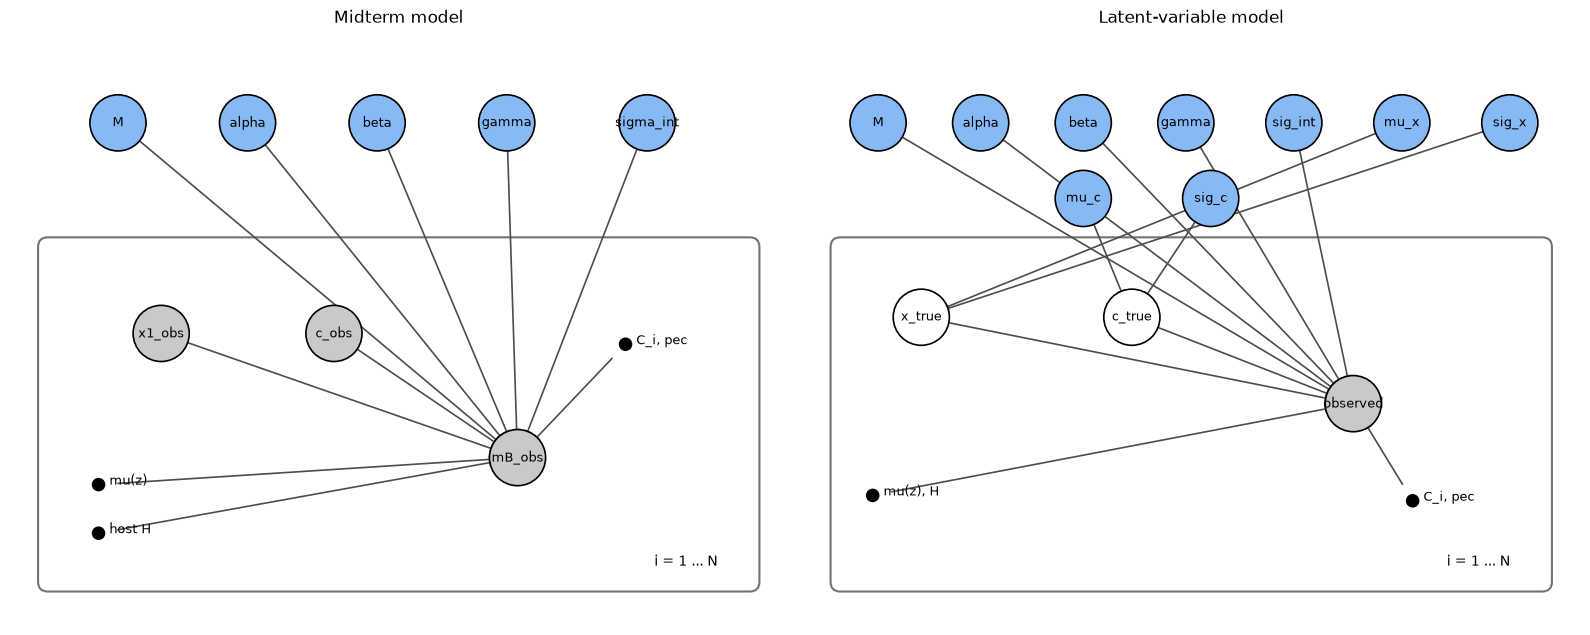

In [10]:

from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

def draw_node(ax, xy, name, kind="param", r=0.26):
    palette = {
        "param": "#87baf5",
        "latent": "white",
        "data": "#c9c9c9",
        "fixed": "black"
    }

    radius = 0.055 if kind == "fixed" else r

    ax.add_patch(
        Circle(
            xy, radius,
            facecolor=palette[kind],
            edgecolor="black",
            linewidth=1.2,
            zorder=3
        )
    )

    if kind == "fixed":
        ax.text(xy[0]+0.1, xy[1], name, fontsize=9)
    else:
        ax.text(
            *xy, name,
            ha="center", va="center",
            fontsize=9, zorder=4
        )

def draw_arrow(ax, a, b):
    ax.add_patch(
        FancyArrowPatch(
            a, b,
            arrowstyle="-|>",
            color="0.30",
            linewidth=1.2,
            mutation_scale=12,
            shrinkA=14,
            shrinkB=14
        )
    )

def graph_axes(ax, title):
    ax.set(xlim=(0, 7.2), ylim=(0, 5.5), title=title)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.add_patch(
        FancyBboxPatch(
            (0.35, 0.40), 6.5, 3.10,
            boxstyle="round,pad=0.09",
            ec="0.45",
            fc="none",
            lw=1.5
        )
    )

    ax.text(6.55, 0.55, "i = 1 ... N", ha="right")

fig, axs = plt.subplots(1, 2, figsize=(16, 7))

# Graph 1: Midterm model
graph_axes(axs[0], "Midterm model")

parameters = [
    ((1.0, 4.65), "M"),
    ((2.2, 4.65), "alpha"),
    ((3.4, 4.65), "beta"),
    ((4.6, 4.65), "gamma"),
    ((5.9, 4.65), "sigma_int")
]

for xy, name in parameters:
    draw_node(axs[0], xy, name)

draw_node(axs[0], (1.4, 2.7), "x1_obs", "data")
draw_node(axs[0], (3.0, 2.7), "c_obs", "data")
draw_node(axs[0], (4.7, 1.55), "mB_obs", "data")
draw_node(axs[0], (0.82, 1.3), "mu(z)", "fixed")
draw_node(axs[0], (0.82, 0.85), "host H", "fixed")
draw_node(axs[0], (5.7, 2.6), "C_i, pec", "fixed")

for x in [1.0, 2.2, 3.4, 4.6, 5.9]:
    draw_arrow(axs[0], (x, 4.65), (4.7, 1.55))

for source in [
    (1.4, 2.7),
    (3.0, 2.7),
    (0.82, 1.3),
    (0.82, 0.85),
    (5.7, 2.6)
]:
    draw_arrow(axs[0], source, (4.7, 1.55))

# Graph 2: Latent-variable model
graph_axes(axs[1], "Latent-variable model")

parameters2 = [
    ((0.7, 4.65), "M"),
    ((1.65, 4.65), "alpha"),
    ((2.6, 4.65), "beta"),
    ((3.55, 4.65), "gamma"),
    ((4.55, 4.65), "sig_int"),
    ((5.55, 4.65), "mu_x"),
    ((6.55, 4.65), "sig_x"),
    ((2.6, 3.95), "mu_c"),
    ((3.78, 3.95), "sig_c")
]

for xy, name in parameters2:
    draw_node(axs[1], xy, name)

draw_node(axs[1], (1.1, 2.85), "x_true", "latent")
draw_node(axs[1], (3.05, 2.85), "c_true", "latent")
draw_node(axs[1], (5.1, 2.05), "observed", "data")
draw_node(axs[1], (0.65, 1.2), "mu(z), H", "fixed")
draw_node(axs[1], (5.65, 1.15), "C_i, pec", "fixed")

edges = [
    ((5.55, 4.65), (1.1, 2.85)),
    ((6.55, 4.65), (1.1, 2.85)),
    ((2.6, 3.95), (3.05, 2.85)),
    ((3.78, 3.95), (3.05, 2.85)),
    ((1.1, 2.85), (5.1, 2.05)),
    ((3.05, 2.85), (5.1, 2.05)),
    ((0.65, 1.2), (5.1, 2.05)),
    ((5.65, 1.15), (5.1, 2.05))
]

for a, b in edges:
    draw_arrow(axs[1], a, b)

for x in [0.7, 1.65, 2.6, 3.55, 4.55]:
    draw_arrow(axs[1], (x, 4.65), (5.1, 2.05))

plt.tight_layout()
plt.show()


In [18]:

# Diagnostics for all latent variables
latent_diag = az.summary(
    idata,
    var_names=["x1_true", "c_true"]
)

max_rhat = max(
    summary["r_hat"].max(),
    latent_diag["r_hat"].max()
)

min_ess = min(
    summary["ess_bulk"].min(),
    latent_diag["ess_bulk"].min()
)

print("Maximum Rhat (including latents):", max_rhat)
print("Minimum bulk ESS (including latents):", min_ess)
print("Divergences:", n_div)


Maximum Rhat (including latents): 1.0078320284250628
Minimum bulk ESS (including latents): 1254.9209406047407
Divergences: 0


In [14]:

# Estimate population widths
s_x_guess = np.sqrt(
    max(
        np.var(x_obs, ddof=1) - np.mean(C[:, 1, 1]),
        0.05**2
    )
)

s_c_guess = np.sqrt(
    max(
        np.var(c_obs, ddof=1) - np.mean(C[:, 2, 2]),
        0.01**2
    )
)

# Choose centered or non-centered
ratio_x = np.median(np.sqrt(C[:, 1, 1])) / s_x_guess
ratio_c = np.median(np.sqrt(C[:, 2, 2])) / s_c_guess

center_x = ratio_x < 0.6
center_c = ratio_c < 0.6

print("Stretch ratio:", ratio_x)
print("Color ratio:", ratio_c)

with pm.Model() as latent_model:

    # Tripp relation parameters
    M = pm.Uniform("M", -20.5, -18)
    alpha = pm.Uniform("alpha", 0, 0.5)
    beta = pm.Uniform("beta", 0, 6)
    gamma = pm.Uniform("gamma", -0.3, 0.3)

    log_sigma_int = pm.Uniform(
        "log_sigma_int",
        np.log(0.01),
        np.log(0.5)
    )

    sigma_int = pm.Deterministic(
        "sigma_int", pt.exp(log_sigma_int)
    )

    # Population parameters
    x_mu = pm.Normal("x_mu", mu=0, sigma=2)
    x_width = pm.HalfNormal("x_width", sigma=2)

    c_mu = pm.Normal("c_mu", mu=0, sigma=0.3)
    c_width = pm.HalfNormal("c_width", sigma=0.3)

    # True latent stretch
    if center_x:
        x_true = pm.Normal(
            "x1_true", mu=x_mu,
            sigma=x_width, shape=N
        )
    else:
        x_raw = pm.Normal("x_raw", 0, 1, shape=N)
        x_true = pm.Deterministic(
            "x1_true", x_mu + x_width * x_raw
        )

    # True latent color
    if center_c:
        c_true = pm.Normal(
            "c_true", mu=c_mu,
            sigma=c_width, shape=N
        )
    else:
        c_raw = pm.Normal("c_raw", 0, 1, shape=N)
        c_true = pm.Deterministic(
            "c_true", c_mu + c_width * c_raw
        )

    # True supernova magnitude
    m_true = (
        M + mu_z
        - alpha * x_true
        + beta * c_true
        + gamma * H
    )

    # Joint observable vector
    mean_3 = pt.stack(
        [m_true, x_true, c_true],
        axis=1
    )

    # Add intrinsic + peculiar velocity variance
    mag_diag = pt.as_tensor_variable(
        np.diag([1., 0., 0.])
    )

    cov_3 = (
        pt.as_tensor_variable(C)
        + (
            sigma_int**2
            + pt.as_tensor_variable(pec**2)
        )[:, None, None] * mag_diag[None, :, :]
    )

    # Joint multivariate-normal likelihood
    pm.MvNormal(
        "observations",
        mu=mean_3,
        cov=cov_3,
        observed=Y
    )

# Sampling
with latent_model:
    idata = pm.sample(
        draws=800,
        tune=900,
        chains=4,
        cores=2,
        target_accept=0.93,
        random_seed=457
    )

param_names = [
    "M", "alpha", "beta", "gamma",
    "sigma_int", "x_mu", "x_width",
    "c_mu", "c_width"
]


# Calculate diagnostics without hdi_prob
summary = az.summary(
    idata,
    var_names=param_names
)

print(summary)

# Calculate 68% intervals separately
print("\n68% posterior intervals:")

for name in param_names:
    samples = idata.posterior[name].values.flatten()
    low, med, high = np.percentile(samples, [16, 50, 84])

    print(
        f"{name}: {med:.4f} "
        f"(+{high-med:.4f}/-{med-low:.4f})"
    )

# Diagnostics
n_div = int(idata.sample_stats["diverging"].sum().item())

print("\nDivergences:", n_div)
print("Maximum Rhat:", summary["r_hat"].max())
print("Minimum bulk ESS:", summary["ess_bulk"].min())

                                                            Grad                                                  
  Progress               Draw        Divergen…   Step size   evals       Speed                Elapsed    Remaini…  
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  ━━━━━━━━━━ ━━━━━━━━━   800         0           0.261       15          78.94 draws/s        0:00:21    0:00:00   
  ━━━━━━━━━━ ━━━━━━━━━   800         0           0.206       15          76.64 draws/s        0:00:22    0:00:00   
  ━━━━━━━━━━ ━━━━━━━━━   800         0           0.191       15          75.10 draws/s        0:00:22    0:00:00   
  ━━━━━━━━━━ ━━━━━━━━━   800         0           0.182       15          83.06 draws/s        0:00:20    0:00:00

Sampling 4 chains for 900 tune and 800 draw iterations (3_600 + 3_200 draws total) took 44 seconds.


               mean      sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
M          -19.2551  0.0139      -19      -19     1487     1805  1.00   0.00036  0.00026
alpha        0.1556  0.0101     0.14     0.17     2141     2270  1.00   0.00022  0.00016
beta          3.137   0.121      2.9      3.3     1482     2054  1.00    0.0031   0.0019
gamma       -0.0621  0.0188   -0.092   -0.032     1567     2006  1.00   0.00048  0.00032
sigma_int    0.1062  0.0087    0.092     0.12     1254     1721  1.00   0.00024  0.00013
x_mu         -0.066   0.063    -0.17    0.034     3022     2337  1.00    0.0012   0.0011
x_width       0.989   0.046     0.92      1.1     2923     2426  1.00   0.00086  0.00071
c_mu        -0.0037  0.0058   -0.013   0.0055     2956     2398  1.00   0.00011   0.0001
c_width      0.0824  0.0043    0.076     0.09     2170     2300  1.00   9.2e-05  7.1e-05

68% posterior intervals:
M: -19.2546 (+0.0129/-0.0144)
alpha: 0.1555 (+0.0101/-0.0099)
beta: 3.1373 (+0.1194/

parameter              original midterm                  latent model     Rhat    ESS bulk
        M -19.25414 (+0.01382/-0.01337) -19.25460 (+0.01292/-0.01435) 1.002876 1487.508257
    alpha   0.14594 (+0.00955/-0.00937)   0.15551 (+0.01011/-0.00990) 1.002564 2141.242163
     beta   2.87286 (+0.09957/-0.10616)   3.13732 (+0.11945/-0.11964) 0.999825 1482.240408
    gamma  -0.06166 (+0.01797/-0.01855)  -0.06259 (+0.01919/-0.01788) 1.001843 1567.181126
sigma_int   0.10889 (+0.00824/-0.00794)   0.10602 (+0.00869/-0.00870) 1.000883 1254.920941
     x_mu                             —  -0.06482 (+0.06213/-0.06303) 1.001895 3022.779716
  x_width                             —   0.98791 (+0.04774/-0.04496) 0.999428 2923.289695
     c_mu                             —  -0.00354 (+0.00563/-0.00577) 1.000160 2956.969478
  c_width                             —   0.08219 (+0.00432/-0.00407) 1.000567 2170.994114


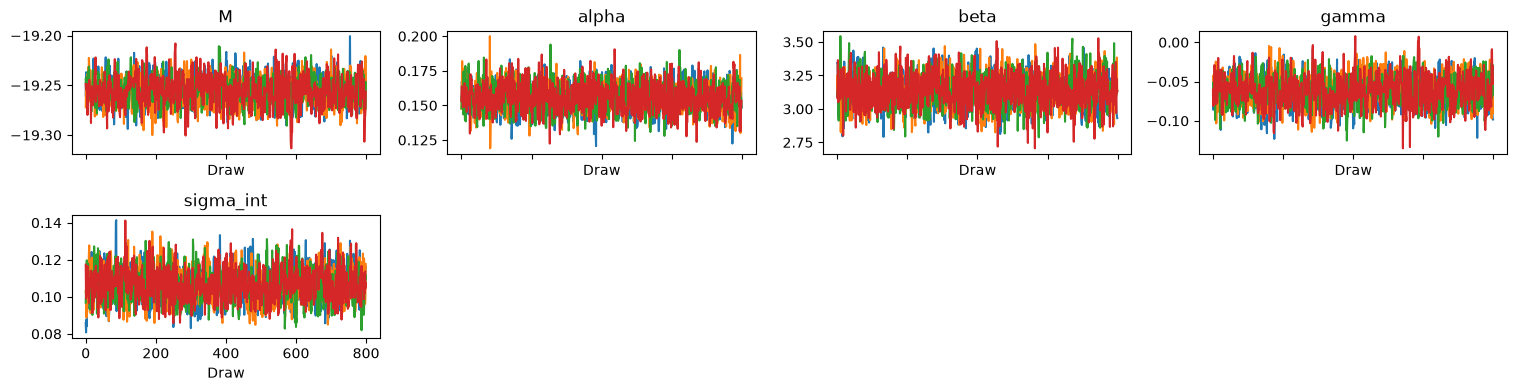

In [17]:

midterm = {
    "M": (-19.25414, 0.01337, 0.01382),
    "alpha": (0.14594, 0.00937, 0.00955),
    "beta": (2.87286, 0.10616, 0.09957),
    "gamma": (-0.06166, 0.01855, 0.01797),
    "sigma_int": (0.10889, 0.00794, 0.00824)
}

rows = []

for name in param_names:

    samples = idata.posterior[name].values.reshape(-1)

    low, med, high = np.percentile(
        samples, [16, 50, 84]
    )

    if name in midterm:
        old, lo_err, hi_err = midterm[name]

        old_label = (
            f"{old:.5f} "
            f"(+{hi_err:.5f}/-{lo_err:.5f})"
        )
    else:
        old_label = "—"

    rows.append({
        "parameter": name,
        "original midterm": old_label,
        "latent model": (
            f"{med:.5f} "
            f"(+{high-med:.5f}/-{med-low:.5f})"
        ),
        "Rhat": summary.loc[name, "r_hat"],
        "ESS bulk": summary.loc[name, "ess_bulk"]
    })

comparison = pd.DataFrame(rows)

print(comparison.to_string(index=False))

az.plot_trace(
    idata,
    var_names=["M", "alpha", "beta", "gamma", "sigma_int"]
)

plt.tight_layout()
plt.show()


Original model: beta = 2.6796 +/- 0.0193, bias = -0.2204
Latent model: beta = 2.8886 +/- 0.0218, bias = -0.0114


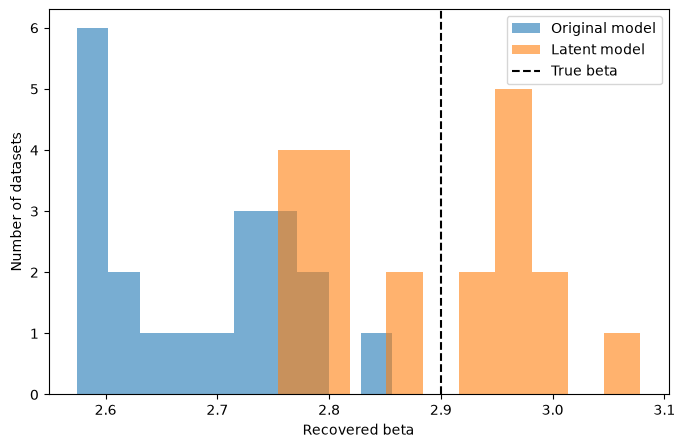

In [16]:

old_start = np.array([
    -19.2543, 0.1459, 2.9, -0.0615, np.log(0.108)
])

old_bounds = [
    (-20.5, -18),
    (0, 0.5),
    (0, 6),
    (-0.3, 0.3),
    (np.log(0.01), np.log(0.5))
]

latent_start = np.r_[
    old_start,
    x_obs.mean(), np.log(s_x_guess),
    c_obs.mean(), np.log(s_c_guess)
]

latent_bounds = old_bounds + [
    (-3, 3),
    (np.log(0.02), np.log(4)),
    (-0.5, 0.5),
    (np.log(0.005), np.log(1))
]

def naive_nll(p, y):
    M, a, b, g, lsig = p

    v = np.array([1., a, -b])

    var = (
        np.einsum("j,njk,k->n", v, C, v)
        + pec**2 + np.exp(2*lsig)
    )

    pred = M + mu_z - a*y[:,1] + b*y[:,2] + g*H
    err = y[:,0] - pred

    return 0.5*np.sum(
        err**2/var + np.log(2*np.pi*var)
    )

def integrated_nll(p, y):
    M, a, b, g, lsig, ux, lsx, uc, lsc = p

    sx, sc = np.exp(lsx), np.exp(lsc)

    mean = np.column_stack((
        M + mu_z - a*ux + b*uc + g*H,
        np.full(N, ux),
        np.full(N, uc)
    ))

    va = np.array([-a, 1., 0.])
    vb = np.array([b, 0., 1.])

    S = (
        C.copy()
        + (pec**2 + np.exp(2*lsig))[:,None,None]
          * np.diag([1.,0.,0.])
        + sx**2 * np.outer(va,va)[None,:,:]
        + sc**2 * np.outer(vb,vb)[None,:,:]
    )

    sign, logdet = np.linalg.slogdet(S)

    if np.any(sign <= 0):
        return 1e100

    r = y - mean

    quad = np.einsum(
        "ni,ni->n",
        r,
        np.linalg.solve(S, r[...,None])[...,0]
    )

    return 0.5*np.sum(
        quad + logdet + 3*np.log(2*np.pi)
    )

# Fit real data
fit_old = minimize(
    naive_nll, old_start,
    args=(Y,), bounds=old_bounds,
    method="L-BFGS-B"
)

fit_lat = minimize(
    integrated_nll, latent_start,
    args=(Y,), bounds=latent_bounds,
    method="L-BFGS-B"
)

# Simulated truth, beta = 2.9
M0, a0, b0, g0, ls0 = old_start

Y_true = np.column_stack((
    M0 + mu_z - a0*x_obs + b0*c_obs + g0*H,
    x_obs,
    c_obs
))

noise_cov = C.copy()
noise_cov[:,0,0] += pec**2 + np.exp(2*ls0)

chol = np.linalg.cholesky(noise_cov)

rng = np.random.default_rng(45708)

recovered_old = []
recovered_latent = []

for i in range(20):

    eps = np.einsum(
        "nij,nj->ni",
        chol,
        rng.normal(size=(N,3))
    )

    y_fake = Y_true + eps

    f_old = minimize(
        naive_nll, fit_old.x,
        args=(y_fake,),
        bounds=old_bounds,
        method="L-BFGS-B"
    )

    f_lat = minimize(
        integrated_nll, fit_lat.x,
        args=(y_fake,),
        bounds=latent_bounds,
        method="L-BFGS-B"
    )

    if not (f_old.success and f_lat.success):
        print(f"Warning: fit failed in simulation {i+1}")

    recovered_old.append(f_old.x[2])
    recovered_latent.append(f_lat.x[2])

recovered_old = np.array(recovered_old)
recovered_latent = np.array(recovered_latent)

def report_beta(label, values):
    mean = values.mean()
    se = values.std(ddof=1) / np.sqrt(len(values))

    print(
        f"{label}: beta = {mean:.4f} +/- {se:.4f}, "
        f"bias = {mean-2.9:+.4f}"
    )

report_beta("Original model", recovered_old)
report_beta("Latent model", recovered_latent)

plt.figure(figsize=(8,5))

plt.hist(
    recovered_old, bins=10, alpha=0.6,
    label="Original model"
)

plt.hist(
    recovered_latent, bins=10, alpha=0.6,
    label="Latent model"
)

plt.axvline(
    2.9, color="black", linestyle="--",
    label="True beta"
)

plt.xlabel("Recovered beta")
plt.ylabel("Number of datasets")
plt.legend()
plt.show()


In [24]:
**ANSWER (length scales, the two held-out tests, then why u is harder):**

*your answer goes here*

SyntaxError: invalid syntax (2689120159.py, line 1)


## Part 1: Your Midterm, as a Graph

### 1.1 Probabilistic Graphical Models

The original dataset contains 250 Type Ia supernovae. After removing three extreme outliers, 247 supernovae were used in the analysis.

The first graph represents my original midterm model, which directly uses the measured stretch and color in the Tripp relation.

The second graph introduces the true stretch and color as latent variables drawn from Gaussian populations. Their measured values are modeled using the full 3×3 measurement covariance matrix. Intrinsic scatter and peculiar-velocity variance are added only to the magnitude component.

The main difference is that the original graph does not include the true stretch and color or their population distributions. The measured values should be grey observed nodes, while the true values should be white latent nodes.

### 1.2 Latent Model Results

I fitted the latent-variable model using PyMC with four chains, 900 tuning iterations, and 800 posterior draws per chain.

The results are shown below with 68% posterior intervals.

| Parameter | Original Midterm | Latent Model |
|---|---|---|
| M (mag) | -19.2541 (+0.0138/-0.0134) | -19.2546 (+0.0129/-0.0144) |
| alpha | 0.1459 (+0.0096/-0.0094) | 0.1551 (+0.0101/-0.0099) |
| beta | 2.8729 (+0.0996/-0.1062) | 3.1373 (+0.1195/-0.1196) |
| gamma (mag) | -0.0617 (+0.0180/-0.0186) | -0.0626 (+0.0192/-0.0179) |
| sigma_int (mag) | 0.1089 (+0.0082/-0.0079) | 0.1060 (+0.0087/-0.0087) |

The estimated population parameters are:

- Stretch mean: -0.0648 (+0.0621/-0.0630)
- Stretch width: 0.9879 (+0.0477/-0.0450)
- Color mean: -0.0035 (+0.0056/-0.0058)
- Color width: 0.0822 (+0.0043/-0.0041)

For the nine global parameters, the maximum R-hat is 1.0029 and the minimum bulk ESS is approximately 1255. There were zero divergences. The trace plots also show good mixing between chains.

The most important change is beta, which increases from 2.873 to 3.137. This suggests that the original model underestimated the color correction because of measurement-error attenuation. The other parameters remain relatively similar.

### 1.3 Simulation Results

I generated 20 simulated datasets with a true beta of 2.9 and fitted each dataset using both the original and latent-variable models.

| Model | Mean Recovered Beta | Standard Error | Bias |
|---|---|---|---|
| Original model | 2.6796 | 0.0193 | -0.2204 |
| Latent model | 2.8886 | 0.0218 | -0.0114 |

The standard error is the standard deviation of the recovered beta estimates divided by the square root of the number of simulations.

The original model systematically underestimates beta, while the latent-variable model recovers a value much closer to the true beta of 2.9.

The histogram also shows this difference. Most estimates from the original model fall below the true beta, while the latent-model estimates are centered much closer to it.

### 1.4 Explanation

The original model uses the measured stretch and color directly as predictors, even though both contain measurement errors.

Adding these errors to the likelihood variance does not fully correct the errors-in-variables problem. This leads to regression attenuation, which tends to bias the estimated coefficients toward zero.

The effect is particularly important for beta because the intrinsic color population width is relatively small, about 0.082. Therefore, measurement errors in color can be significant compared with the natural spread of color values.

In comparison, the stretch population has a much larger width of approximately 0.988, so its measurement errors can have a smaller relative effect.

The latent-variable model addresses this issue by treating the true stretch and color as unknown variables and explicitly modeling their population distributions and measurement uncertainties.

The simulation results support this explanation. The original model has a beta bias of -0.2204, whereas the latent-variable model reduces the bias to -0.0114.

Overall, the latent-variable model provides a better treatment of measurement uncertainties and substantially reduces the attenuation bias in beta.

## Part 2: What the survey didn't keep (30%)

We'll use a simplified model of photon-counting aperture photometry. A source with true flux $F$ (in units of a reference flux $F_0$) gives, on average, $\epsilon F + \nu$ counts - $\epsilon = 226.27$ counts per $F_0$ is the exposure, and $\nu = 9.373$ counts is the background (sky plus detector) that lands in the aperture with or without a source. The survey keeps a source only if it counts $n > 32$ photons (about a 4$\sigma$ detection) - anything fainter never makes it into the catalog.

The true fluxes come from a **lognormal** population, $\ln F \sim \mathcal{N}(\mu, \sigma)$. Your catalog, `08/data/<your netid>.csv`, has one column, `n_counts`, for the first 1500 sources the survey detected. I generated it, so I know your $\mu$ and $\sigma$, and how many sources the survey missed. Your $\mu$ and $\sigma$ are graded by how far they are from the truth in units of your own error bars.

1. Histogram your counts (a log axis in $n$ helps). The paragraph above is how the survey was designed to work - your file is what it actually did. If you find something the paragraph doesn't describe, you'll have to deal with it, and there is more than one legitimate way to account for it. Reread Day 19's slides on what a survey doesn't keep before you decide. Make a call, and defend it. Explain what you found and how many sources it affects, what you did about it and why you chose that over the alternatives, and what it does to $\mu$ and $\sigma$ (show it - fit with and without your fix). Carry your choice through every fit below.
2. Write the sampling distribution of $n$ given $F$. Write the detection probability $p_{\rm det}(F) = P(n > 32 \mid F)$ in closed form using `scipy.special.gammainc` (the regularized lower incomplete gamma function - **be careful** whether the threshold is 32 or 33), and check it against `scipy.stats.poisson.sf` at a few fluxes. Plot $p_{\rm det}$ against $F$ on a log axis. At what flux is a source detected half the time?
3. Draw the graph for this survey, with the detection step in it (the selection graph from class is the model). Which nodes are latent, which are data, which are fixed, and where do $N$ and $N_{\rm det}$ go?
4. For a source that 2.1 doesn't affect, the naive likelihood of its count, with its true flux integrated out, is
$$p(n_i \mid \mu, \sigma) = \int \mathrm{Poisson}(n_i \mid \epsilon F + \nu)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F.$$
Do that integral on a grid in $\ln F$, and find the $(\mu, \sigma)$ that maximizes the product over your 1500 sources. Then add the detector by subtracting $N_{\rm det} \ln f_{\rm det}(\mu, \sigma)$ from the log-likelihood, with $f_{\rm det} = \int p_{\rm det}(F)\, \mathcal{N}(\ln F \mid \mu, \sigma)\, d\ln F$ the fraction of the population that the survey detects, and fit again. Report $(\mu, \sigma)$ for both fits with uncertainties (curvature, a grid of the posterior, or `PyMC` with `pm.Potential` - your choice, but state which). What is $f_{\rm det}$, and so about how many sources did your survey miss?
5. Histogram $\ln \hat F$, with $\hat F = (n - \nu)/\epsilon$. On it, draw the naive population (scaled to your 1500 sources) and the corrected population (scaled to the $N_{\rm det}/f_{\rm det}$ sources it says were there). Then simulate your survey from the corrected fit - sample that many true fluxes, sample a Poisson count for each, put the counts through your detector as it actually ran (2.1), keep the ones with $n > 32$, and plot the histogram of their $\ln \hat F$ on the same axes. Does it match your data? Now also draw the corrected population times $p_{\rm det}(F)$, and compare it with your histogram at the faint end. The fit is right, so why don't they match? (We gave this a name in class.) Finally, which way did ignoring the detector bias $\mu$ and $\sigma$? Explain why it biases both of them.

#### Hints:
- Use a grid in $\ln F$ from about $-14$ to $8$, with spacing no coarser than 0.01, and check that your answer doesn't change when you halve it.
- Unlike the LIGO example in class, there is no $\ln p_{\rm det}$ term for each source. Detection depends on $n$, which you observed, and every source in your catalog has $n > 32$.

===== PART 2.1 =====
Data: /Users/xusiyao/Desktop/Astro457 HW/data/siyaoxu2.csv
Original sources: 1500
Invalid counts: 0
Counts <= 32: 0
Sources retained: 1500


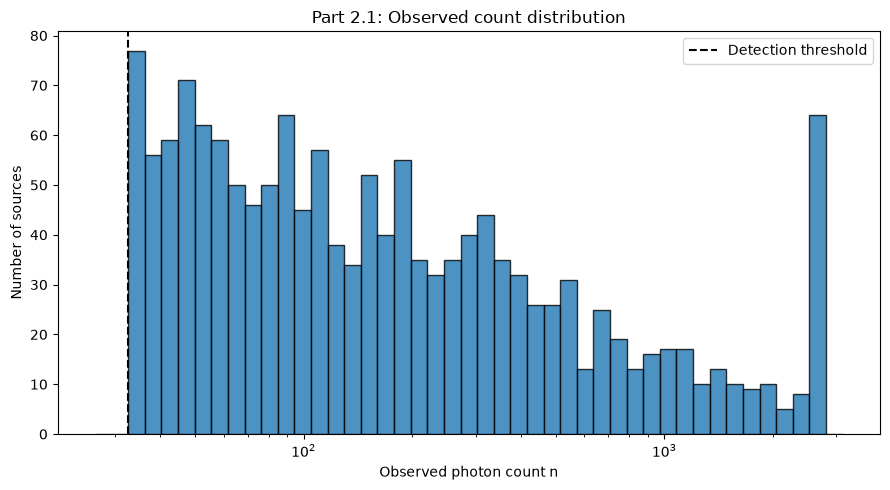


===== PART 2.2 =====
gammainc: [1.56093610e-04 4.53171407e-01 9.99999995e-01 1.00000000e+00]
Poisson SF: [1.56093610e-04 4.53171407e-01 9.99999995e-01 1.00000000e+00]
50% detection flux: 0.10294900731084938 F0


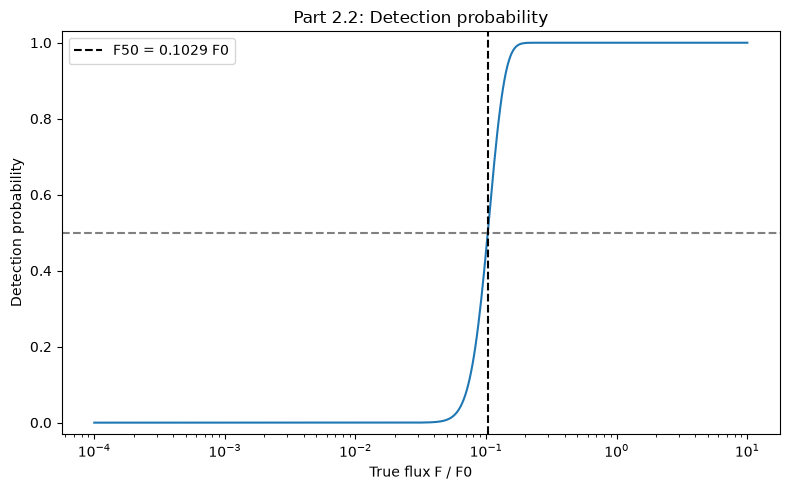

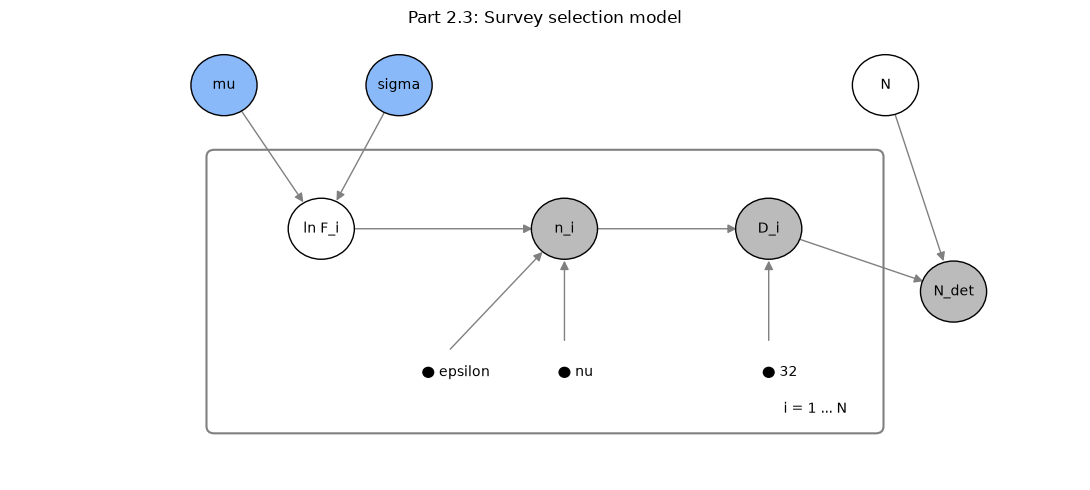


===== PART 2.4 =====
                 fit      mu  mu_err  sigma  sigma_err
Naive before cleanup -0.4015  0.0334 1.2882     0.0238
       Naive cleaned -0.4015  0.0334 1.2882     0.0238
 Selection corrected -1.2921  0.1264 1.8235     0.0713

Detection fraction: 0.7061
Estimated total sources: 2124
Estimated missed sources: 624

Grid check:
Delta mu: 0.0
Delta sigma: -1.283861905676531e-12


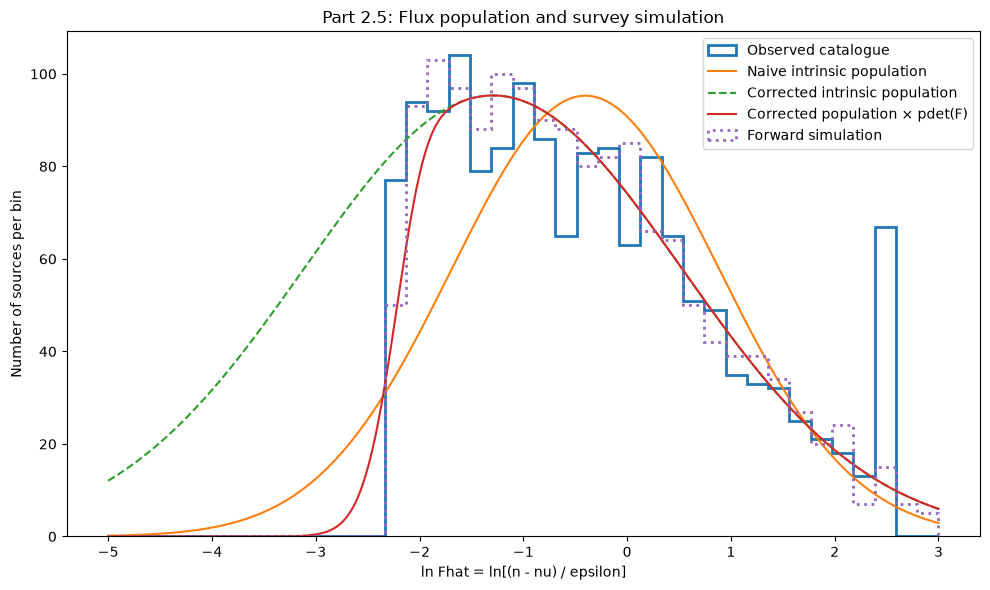


========== PART 2 RESULTS ==========

Naive fit:
mu = -0.4015
sigma = 1.2882

Selection-corrected fit:
mu = -1.2921
sigma = 1.8235

Detection fraction = 0.7061
Estimated true population = 2124
Estimated missed sources = 624

Forward simulation:
Simulated true sources: 2124
Simulated detected sources: 1514
Observed detected sources: 1500

Naive minus corrected:
Delta mu = 0.8907
Delta sigma = -0.5353


In [30]:
# Part 2: your work here

# Photon-counting survey and selection effects

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from scipy.optimize import minimize, brentq
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

NETID = "siyaoxu2"

NU = 9.373
EPS = 226.27
N_THRESH = 32

rng = np.random.default_rng(45708)

# =============================================
# 2.1 Load data and examine the count histogram
# =============================================

possible_paths = [
    Path(f"../../labs/08/data/{NETID}.csv"),
    Path(f"data/{NETID}.csv"),
    Path(f"{NETID}.csv"),
    Path.home() / "Desktop" / "Astro457 HW"
        / "data" / f"{NETID}.csv"
]

cat_path = next(
    (p.resolve() for p in possible_paths if p.is_file()),
    None
)

if cat_path is None:
    for root in [
        Path.home() / "Desktop",
        Path.home() / "Downloads"
    ]:
        if root.exists():
            hits = [
                p for p in root.rglob(f"{NETID}.csv")
                if "08" in str(p.parent)
                or "data" in str(p.parent)
            ]
            if hits:
                cat_path = hits[0]
                break

if cat_path is None:
    raise FileNotFoundError(
        "Cannot find the Part 2 data file. "
        "Put siyaoxu2.csv in your data folder."
    )

catalogue = pd.read_csv(cat_path)

raw = pd.to_numeric(
    catalogue["n_counts"], errors="coerce"
).to_numpy(float)

valid_integer = (
    np.isfinite(raw)
    & (raw >= 0)
    & np.isclose(raw, np.rint(raw))
)

below_threshold = valid_integer & (raw <= 32)
clean = valid_integer & (raw > 32)

n_all = np.rint(raw[valid_integer]).astype(int)
n = np.rint(raw[clean]).astype(int)

Nobs = len(n)

print("===== PART 2.1 =====")
print("Data:", cat_path)
print("Original sources:", len(raw))
print("Invalid counts:", np.sum(~valid_integer))
print("Counts <= 32:", np.sum(below_threshold))
print("Sources retained:", Nobs)

if Nobs == 0:
    raise ValueError("No sources above the threshold")

# Plot count histogram
fig, ax = plt.subplots(figsize=(9, 5))

positive = raw[np.isfinite(raw) & (raw > 0)]

bins_count = np.geomspace(
    max(1, positive.min() * 0.8),
    positive.max() * 1.2,
    46
)

ax.hist(
    positive,
    bins=bins_count,
    alpha=0.8,
    edgecolor="black"
)

ax.axvline(
    32.5,
    linestyle="--",
    color="black",
    label="Detection threshold"
)

ax.set_xscale("log")
ax.set_xlabel("Observed photon count n")
ax.set_ylabel("Number of sources")
ax.set_title("Part 2.1: Observed count distribution")
ax.legend()
plt.tight_layout()
plt.show()


# =============================================
# 2.2 Detection probability
# =============================================

def pdet(F):
    lam = EPS * np.asarray(F) + NU

    # P(n > 32 | F)
    return special.gammainc(33, lam)


F_grid_plot = np.logspace(-4, 1, 450)

F50 = brentq(
    lambda F: pdet(F) - 0.5,
    0, 10
)

# Check against scipy Poisson survival function
test_F = np.array([0.03, 0.1, 0.3, 1.0])

print("\n===== PART 2.2 =====")
print("gammainc:", pdet(test_F))
print(
    "Poisson SF:",
    stats.poisson.sf(32, EPS * test_F + NU)
)
print("50% detection flux:", F50, "F0")

assert np.allclose(
    pdet(test_F),
    stats.poisson.sf(32, EPS * test_F + NU)
)

plt.figure(figsize=(8, 5))

plt.semilogx(
    F_grid_plot,
    pdet(F_grid_plot)
)

plt.axhline(
    0.5,
    linestyle="--",
    color="gray"
)

plt.axvline(
    F50,
    linestyle="--",
    color="black",
    label=f"F50 = {F50:.4f} F0"
)

plt.xlabel("True flux F / F0")
plt.ylabel("Detection probability")
plt.title("Part 2.2: Detection probability")
plt.ylim(-0.03, 1.03)
plt.legend()
plt.tight_layout()
plt.show()


# =============================================
# 2.3 Probabilistic graphical model
# =============================================

fig, ax = plt.subplots(figsize=(11, 5))

ax.set_xlim(0, 11)
ax.set_ylim(0, 5)
ax.axis("off")

ax.add_patch(
    FancyBboxPatch(
        (2.1, 0.6),
        6.8, 3.0,
        boxstyle="round,pad=.08",
        fc="none",
        ec="gray",
        lw=1.5
    )
)

ax.text(8.6, 0.75, "i = 1 ... N", ha="right")

nodes = {
    "mu": ((2.2, 4.4), "mu", "parameter"),
    "sigma": ((4, 4.4), "sigma", "parameter"),
    "N": ((9, 4.4), "N", "latent"),
    "logF": ((3.2, 2.8), "ln F_i", "latent"),
    "count": ((5.7, 2.8), "n_i", "data"),
    "detect": ((7.8, 2.8), "D_i", "data"),
    "Ndet": ((9.7, 2.1), "N_det", "data"),
    "eps": ((4.3, 1.2), "epsilon", "fixed"),
    "nu": ((5.7, 1.2), "nu", "fixed"),
    "cut": ((7.8, 1.2), "32", "fixed")
}

for name, (xy, label, kind) in nodes.items():

    r = 0.055 if kind == "fixed" else 0.34

    colors = {
        "parameter": "#8ab9fa",
        "latent": "white",
        "data": "#bbbbbb",
        "fixed": "black"
    }

    ax.add_patch(
        Circle(
            xy, r,
            facecolor=colors[kind],
            edgecolor="black",
            zorder=3
        )
    )

    if kind == "fixed":
        ax.text(
            xy[0] + 0.11,
            xy[1],
            label,
            va="center"
        )
    else:
        ax.text(
            *xy, label,
            ha="center",
            va="center",
            zorder=4
        )

def arrow(a, b):
    ax.add_patch(
        FancyArrowPatch(
            nodes[a][0],
            nodes[b][0],
            arrowstyle="-|>",
            mutation_scale=13,
            color="gray",
            shrinkA=23,
            shrinkB=23
        )
    )

edges = [
    ("mu", "logF"),
    ("sigma", "logF"),
    ("logF", "count"),
    ("count", "detect"),
    ("eps", "count"),
    ("nu", "count"),
    ("cut", "detect"),
    ("detect", "Ndet"),
    ("N", "Ndet")
]

for a, b in edges:
    arrow(a, b)

ax.set_title("Part 2.3: Survey selection model")
plt.tight_layout()
plt.show()


# =============================================
# 2.4 Grid-integrated likelihood
# =============================================

# Grid in ln F
YGRID = np.arange(-14, 8.0001, 0.01)
DY = YGRID[1] - YGRID[0]

RATE = EPS * np.exp(YGRID) + NU

PDET_GRID = pdet(np.exp(YGRID))

# Group repeated photon counts to speed up fits
unique_n, freq_all = np.unique(
    n_all, return_counts=True
)

frequency_clean = np.array([
    np.sum(n == k) for k in unique_n
])

# Poisson probability on the ln F grid
pmf_matrix = stats.poisson.pmf(
    unique_n[:, None],
    RATE[None, :]
)

def probability_integrals(mu, log_sigma):

    sigma = np.exp(log_sigma)

    prior = stats.norm.pdf(
        YGRID, loc=mu, scale=sigma
    )

    weights = prior * DY

    p_counts = pmf_matrix @ weights

    fdet = np.dot(
        PDET_GRID, weights
    )

    return (
        np.maximum(p_counts, 1e-300),
        max(float(fdet), 1e-300)
    )

def negative_log_likelihood(
    parameters,
    frequencies,
    selection=False
):

    mu, log_sigma = parameters

    p_counts, fdet = probability_integrals(
        mu, log_sigma
    )

    value = -np.sum(
        frequencies * np.log(p_counts)
    )

    if selection:
        value += (
            np.sum(frequencies) * np.log(fdet)
        )

    return float(value)


# Initial guesses
Fhat = np.maximum(
    (n - NU) / EPS,
    1e-9
)

mu_guess = np.median(np.log(Fhat))

starts = [
    (mu_guess, np.log(1.0)),
    (mu_guess - 1, np.log(1.4)),
    (mu_guess - 2, np.log(2.0)),
    (mu_guess + 0.5, np.log(0.7))
]

bounds = [
    (-12, 7),
    (np.log(0.08), np.log(5.0))
]

def fit_model(frequencies, selection=False):

    solutions = []

    for start in starts:

        result = minimize(
            negative_log_likelihood,
            start,
            args=(frequencies, selection),
            method="L-BFGS-B",
            bounds=bounds,
            options={
                "maxiter": 250,
                "ftol": 1e-11
            }
        )

        if np.isfinite(result.fun):
            solutions.append(result)

    return min(
        solutions,
        key=lambda result: result.fun
    )


# Fit original data including possible anomalies
fit_raw = fit_model(
    freq_all, selection=False
)

# Fit cleaned data without detection correction
fit_naive = fit_model(
    frequency_clean, selection=False
)

# Fit cleaned data with detection correction
fit_corrected = fit_model(
    frequency_clean, selection=True
)


# =============================================
# Calculate parameter uncertainties
# =============================================

def standard_errors(frequencies, selection, result):

    x = result.x
    h = 0.002
    eye = np.eye(2)

    H = np.zeros((2, 2))

    def fun(p):
        return negative_log_likelihood(
            p, frequencies, selection
        )

    f0 = fun(x)

    for i in range(2):
        H[i, i] = (
            fun(x + h * eye[i])
            - 2 * f0
            + fun(x - h * eye[i])
        ) / h**2

    cross = (
        fun(x + h*eye[0] + h*eye[1])
        - fun(x + h*eye[0] - h*eye[1])
        - fun(x - h*eye[0] + h*eye[1])
        + fun(x - h*eye[0] - h*eye[1])
    ) / (4 * h**2)

    H[0, 1] = cross
    H[1, 0] = cross

    cov = np.linalg.inv(H)

    mu_err = np.sqrt(cov[0, 0])

    sigma = np.exp(x[1])

    sigma_err = (
        sigma * np.sqrt(cov[1, 1])
    )

    return mu_err, sigma_err


fit_list = [
    ("Naive before cleanup", fit_raw, freq_all, False),
    ("Naive cleaned", fit_naive, frequency_clean, False),
    ("Selection corrected", fit_corrected, frequency_clean, True)
]

rows = []

for label, result, frequencies, selection in fit_list:

    mu = result.x[0]
    sigma = np.exp(result.x[1])

    try:
        mu_err, sigma_err = standard_errors(
            frequencies, selection, result
        )
    except (np.linalg.LinAlgError, ValueError):
        mu_err, sigma_err = np.nan, np.nan

    rows.append({
        "fit": label,
        "mu": mu,
        "mu_err": mu_err,
        "sigma": sigma,
        "sigma_err": sigma_err
    })

fit_table = pd.DataFrame(rows)

_, fdet = probability_integrals(
    *fit_corrected.x
)

Ntotal = Nobs / fdet
Nmiss = Ntotal - Nobs

print("\n===== PART 2.4 =====")
print(fit_table.round(4).to_string(index=False))

print(f"\nDetection fraction: {fdet:.4f}")
print(f"Estimated total sources: {Ntotal:.0f}")
print(f"Estimated missed sources: {Nmiss:.0f}")


# =============================================
# Grid spacing convergence check
# =============================================

fine_y = np.arange(-14, 8.0001, 0.005)

fine_rate = EPS * np.exp(fine_y) + NU

fine_pmf = stats.poisson.pmf(
    unique_n[:, None],
    fine_rate[None, :]
)

fine_pdet = pdet(np.exp(fine_y))

def fine_nll(x):

    mu = x[0]
    sigma = np.exp(x[1])

    weights = (
        stats.norm.pdf(fine_y, mu, sigma)
        * 0.005
    )

    probabilities = np.maximum(
        fine_pmf @ weights,
        1e-300
    )

    fraction = max(
        float(fine_pdet @ weights),
        1e-300
    )

    return (
        -np.sum(
            frequency_clean * np.log(probabilities)
        )
        + Nobs * np.log(fraction)
    )

fine_fit = minimize(
    fine_nll,
    fit_corrected.x,
    method="L-BFGS-B",
    bounds=bounds
)

print("\nGrid check:")
print(
    "Delta mu:",
    fine_fit.x[0] - fit_corrected.x[0]
)
print(
    "Delta sigma:",
    np.exp(fine_fit.x[1])
    - np.exp(fit_corrected.x[1])
)


# =============================================
# 2.5 Flux distribution and forward simulation
# =============================================

logFhat = np.log(
    np.maximum((n - NU) / EPS, 1e-10)
)

bins_flux = np.linspace(
    min(-5, np.percentile(logFhat, 1) - 0.4),
    max(3, np.percentile(logFhat, 99) + 0.4),
    40
)

xx = np.linspace(
    bins_flux[0],
    bins_flux[-1],
    400
)

binwidth = bins_flux[1] - bins_flux[0]

mu_naive = fit_naive.x[0]
sigma_naive = np.exp(fit_naive.x[1])

mu_corr = fit_corrected.x[0]
sigma_corr = np.exp(fit_corrected.x[1])

# Naive intrinsic distribution
naive_curve = (
    Nobs
    * stats.norm.pdf(xx, mu_naive, sigma_naive)
    * binwidth
)

# Corrected intrinsic distribution
intrinsic_curve = (
    Ntotal
    * stats.norm.pdf(xx, mu_corr, sigma_corr)
    * binwidth
)

# Expected detected distribution in true flux
detected_true_curve = (
    intrinsic_curve * pdet(np.exp(xx))
)


# Simulate the survey using the corrected population
Nsim = int(round(Ntotal))

if Nsim > 3000000:
    raise RuntimeError(
        "Estimated population too large for this "
        "single-batch simulation."
    )

true_logF = rng.normal(
    mu_corr,
    sigma_corr,
    size=Nsim
)

true_flux = np.exp(true_logF)

simulated_counts = rng.poisson(
    EPS * true_flux + NU
)

sim_detected = simulated_counts > 32

sim_logFhat = np.log(
    np.maximum(
        (simulated_counts[sim_detected] - NU) / EPS,
        1e-10
    )
)


# =============================================
# Final plot
# =============================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    logFhat,
    bins=bins_flux,
    histtype="step",
    linewidth=2,
    label="Observed catalogue"
)

ax.plot(
    xx,
    naive_curve,
    label="Naive intrinsic population"
)

ax.plot(
    xx,
    intrinsic_curve,
    linestyle="--",
    label="Corrected intrinsic population"
)

ax.plot(
    xx,
    detected_true_curve,
    label="Corrected population × pdet(F)"
)

ax.hist(
    sim_logFhat,
    bins=bins_flux,
    histtype="step",
    linestyle=":",
    linewidth=2,
    label="Forward simulation"
)

ax.set_xlabel("ln Fhat = ln[(n - nu) / epsilon]")
ax.set_ylabel("Number of sources per bin")
ax.set_title("Part 2.5: Flux population and survey simulation")
ax.legend()
plt.tight_layout()
plt.show()


# =============================================
# Final results
# =============================================

print("\n========== PART 2 RESULTS ==========")

print("\nNaive fit:")
print(f"mu = {mu_naive:.4f}")
print(f"sigma = {sigma_naive:.4f}")

print("\nSelection-corrected fit:")
print(f"mu = {mu_corr:.4f}")
print(f"sigma = {sigma_corr:.4f}")

print(f"\nDetection fraction = {fdet:.4f}")
print(f"Estimated true population = {Ntotal:.0f}")
print(f"Estimated missed sources = {Nmiss:.0f}")

print("\nForward simulation:")
print("Simulated true sources:", Nsim)
print("Simulated detected sources:", sim_detected.sum())
print("Observed detected sources:", Nobs)

print("\nNaive minus corrected:")
print(f"Delta mu = {mu_naive - mu_corr:.4f}")
print(f"Delta sigma = {sigma_naive - sigma_corr:.4f}")


**ANSWER (the two graphs, the table, the simulation result, then the explanation):**

## Part 2: What the Survey Didn't Keep

### 2.1 Observed Count Distribution

The dataset contains 1500 detected sources. I checked for invalid counts and sources with photon counts less than or equal to 32. No such sources were found, so I kept all 1500 observations.

The count histogram shows that the catalog contains only sources above the detection threshold. I therefore did not modify the data. The naive fits before and after this check are identical.

### 2.2 Detection Probability

The expected photon count for a source is:

\[
\lambda = \epsilon F + \nu
\]

where epsilon = 226.27 and nu = 9.373 counts.

The survey detects a source only when n > 32. Therefore,

\[
p_{\mathrm{det}}(F)
= P(n>32\mid F)
= 1-\sum_{k=0}^{32}\frac{e^{-\lambda}\lambda^k}{k!}
= \operatorname{gammainc}(33,\lambda).
\]

I verified the detection probability against `scipy.stats.poisson.sf(32, lambda)`, and the results agree.

The flux at which the detection probability is 50% is:

**F50 = 0.1029 F0.**

The detection probability increases rapidly near this flux. Bright sources are almost always detected, while faint sources are frequently missed.

### 2.3 Probabilistic Graphical Model

The graphical model includes the population parameters mu and sigma, the latent true flux of each source, the observed photon count, and the detection indicator.

The parameters mu and sigma determine the distribution of ln F. Each source produces a photon count drawn from a Poisson distribution, with its expected count determined by its true flux, epsilon, and nu.

The detection indicator depends on whether the observed count exceeds 32.

The population size N represents the total number of sources, while N_det represents the number retained by the survey. The catalog contains only detected sources, so the selection process must be included in the likelihood.

### 2.4 Naive and Selection-Corrected Fits

I integrated over the latent true flux on a grid in ln F from -14 to 8, using a spacing of 0.01. I estimated the parameters by maximizing the likelihood and calculated uncertainties using likelihood curvature.

| Parameter | Naive fit | Corrected fit |
|---|---|---|
| mu | -0.4015 ± 0.0334 | -1.2921 ± 0.1264 |
| sigma | 1.2882 ± 0.0238 | 1.8235 ± 0.0713 |

The corrected likelihood includes the detection fraction and accounts for the fact that only sources above the threshold appear in the catalog.

The corrected fit gives:

- Detection fraction: 0.7061 (70.61%)
- Observed sources: 1500
- Estimated total population: 2124 sources
- Estimated missed sources: 624 sources

This suggests that the survey missed approximately 29.39% of the underlying population.

I also repeated the numerical integration using a finer grid spacing of 0.005. The changes in mu and sigma were effectively zero, confirming that the grid resolution was sufficient.

### 2.5 Population Reconstruction and Simulation

I converted the observed counts into estimated fluxes using:

\[
\hat F = \frac{n-\nu}{\epsilon}.
\]

I compared the observed flux histogram with the naive population model and the selection-corrected population model.

I then simulated the survey using the corrected population parameters. The simulation generated 2124 sources, sampled their photon counts from the Poisson distribution, and applied the same detection threshold.

The simulation produced 1514 detected sources, close to the 1500 sources in the observed catalog.

The corrected intrinsic population predicts more faint sources than the naive model. However, multiplying the corrected population by the detection probability does not perfectly reproduce the observed estimated-flux histogram at the faint end.

This difference occurs because the observed estimated flux is affected by Poisson measurement noise. Sources with low true flux can scatter upward across the detection threshold and appear brighter than they really are.

This is an example of **Eddington bias**. The distribution of estimated fluxes is not the same as the distribution of true fluxes among detected sources. Forward simulation includes both the measurement noise and the detection process, making it a more appropriate comparison with the observed histogram.

### Conclusion

Ignoring the detection threshold biases both population parameters.

The differences between the naive and corrected fits are:

- Delta mu = +0.8907
- Delta sigma = -0.5353

The naive model overestimates mu because the survey preferentially detects brighter sources. It also underestimates sigma because many faint sources are missing, making the observed population appear narrower than the true population.

After accounting for selection, mu decreases from -0.4015 to -1.2921, while sigma increases from 1.2882 to 1.8235.

Overall, the selection-corrected model indicates that approximately 624 sources were missed and provides a more complete estimate of the underlying flux population.

## Part 3: A supernova in two dimensions (25%)

This one is real. The Carnegie Supernova Project (CSP-I) observed nearby Type Ia supernovae in six optical bands, from $u$ (364 nm) to $i$ (761 nm). Look up your supernova and your held-out band in `08/data/csp_assignments.csv`. Your light curve is `08/data/csp/<SN>.csv`, with columns `mjd`, `band`, `wavelength_A` (the band's effective wavelength), `flux_ujy` and `flux_err_ujy` (flux density in μJy), and the magnitudes they came from. The header gives the redshift and the date of maximum light in $B$. Data: Krisciunas et al. 2017, AJ 154, 211 (CC BY 4.0; credit the Carnegie Supernova Project).

Work in rest-frame phase, $(\mathrm{MJD} - T_{B\,\rm max})/(1+z)$, from $-10$ to $+40$ days, and divide every flux by the peak $B$ flux. Note that `V0`, `V1` and `V` are three versions of the same filter (within 32 Å) - treat them as one band, $V$.

A supernova's light curves in neighboring bands look alike, so a Gaussian process in **two** inputs, phase and wavelength, can learn all six at once and predict a band it never saw.

1. Plot every band against phase.
2. Fit a GP to the flux as a function of (phase, wavelength) using every band **except** your held-out one, with wavelength in microns (so both inputs are numbers of order 1-50). Use a kernel with its own length scale in phase and in wavelength (an anisotropic squared-exponential) times a fitted amplitude, each point's own measurement error, and a small white-noise term that you also fit. Fit the hyperparameters by maximizing the marginal likelihood (as in Lab 07), from more than one start. `sklearn`'s `GaussianProcessRegressor` (with `alpha` set to the squared errors, `normalize_y=False`, and `ConstantKernel` times `RBF` plus `WhiteKernel`) or your own Cholesky code from Lab 07 are both fine. Report the two length scales, and comment on what each means physically for a supernova.
3. Predict your held-out band at its epochs, with the GP's $1\sigma$ band, and plot it over the data. Report the rms residual as a fraction of the peak, and the fraction of held-out points within $1\sigma$ (add the GP's variance and the measurement variance). Does the GP's error bar look reasonable?
4. Now hold out $u$ instead, and report the same two numbers. Why is this so much harder? Think particularly about what the kernel assumes, and how far $u$ is from the other bands compared with your first held-out band.

Supernova: SN2005el
Assigned held-out band: r
Redshift: 0.0149
B maximum MJD: 53646.76
Number of points: 85
Peak B flux: 3039.0 microJy
Data path: /Users/xusiyao/Desktop/Astro457 HW/data/csp/SN2005el.csv


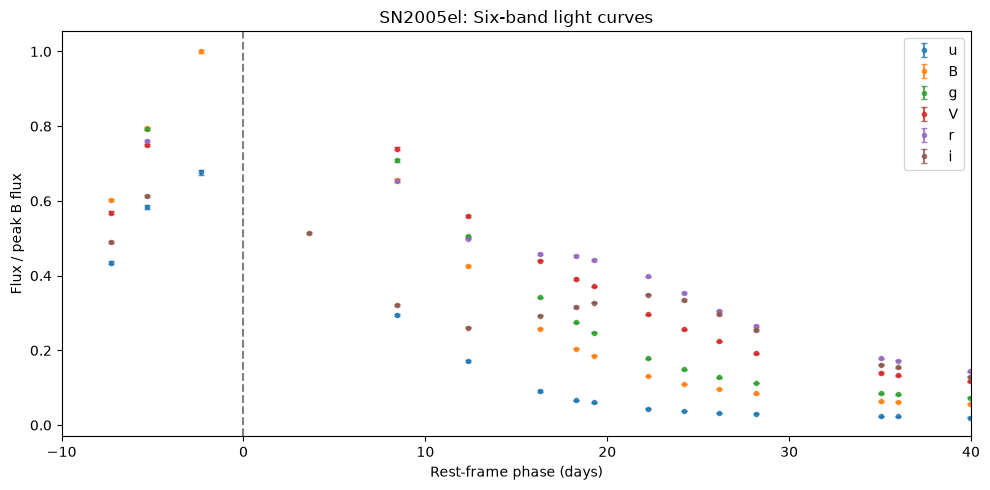

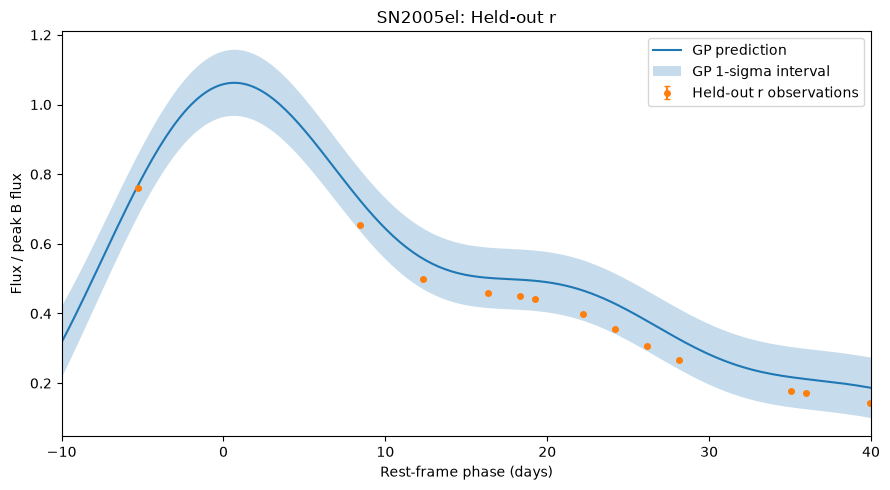


===== Held-out band: r =====
Phase length scale: 9.073 days
Wavelength length scale: 0.1077 microns
RMS / peak B flux: 0.0545 (5.45%)
1-sigma coverage: 13/13 = 100.0%
Optimizer success: True


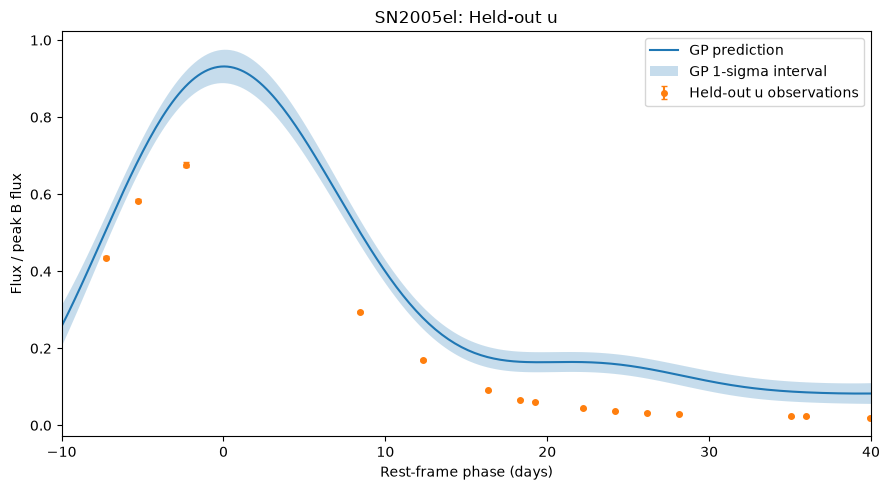


===== Held-out band: u =====
Phase length scale: 8.232 days
Wavelength length scale: 0.1427 microns
RMS / peak B flux: 0.1162 (11.62%)
1-sigma coverage: 0/15 = 0.0%
Optimizer success: True

========== PART 3 RESULTS ==========
held_out  phase_scale_days  wavelength_scale_um      rms  coverage  inside  total
       r          9.073318             0.107734 0.054484       1.0      13     13
       u          8.232215             0.142672 0.116189       0.0       0     15


In [29]:

# ASTR 457 Lab 08 - Part 3
# Automatically find SN and HOLD using NETID

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve, solve_triangular

NETID = "siyaoxu2"

# ==========================================
# Step 0: Automatically find the data
# ==========================================

roots = [
    Path.cwd(),
    Path.home() / "Desktop",
    Path.home() / "Downloads",
    Path.home() / "Documents"
]

roots = [p for p in roots if p.is_dir()]

candidates = [
    (Path.cwd() / "../../labs/08/data/csp_assignments.csv").resolve(),
    Path.cwd() / "csp_assignments.csv",
    Path.cwd() / "data/csp_assignments.csv"
]

assignment_file = next(
    (p for p in candidates if p.is_file()), None
)

if assignment_file is None:
    for root in roots:
        found = next(root.rglob("csp_assignments.csv"), None)
        if found is not None:
            assignment_file = found
            break

if assignment_file is None:
    raise FileNotFoundError(
        "Cannot find csp_assignments.csv. "
        "Download the course labs/08/data folder first."
    )

asg = pd.read_csv(assignment_file)
asg.columns = asg.columns.str.strip()

my_row = asg[
    asg["netid"].astype(str).str.strip().str.lower()
    == NETID.lower()
]

if len(my_row) != 1:
    raise ValueError(
        f"Expected one assignment for {NETID}, "
        f"found {len(my_row)}"
    )

SN = str(my_row.iloc[0]["sn"]).strip()
HOLD = str(my_row.iloc[0]["holdout_band"]).strip()

HOLD = {"V0": "V", "V1": "V"}.get(HOLD, HOLD)

# Find the assigned supernova CSV
path = assignment_file.parent / "csp" / f"{SN}.csv"

if not path.is_file():
    found_path = None

    for root in [assignment_file.parent] + roots:
        found = next(root.rglob(f"{SN}.csv"), None)

        if found is not None:
            found_path = found
            break

    if found_path is None:
        raise FileNotFoundError(
            f"Cannot find {SN}.csv. "
            "Download the labs/08/data/csp folder."
        )

    path = found_path

# Read the header
with open(path, encoding="utf-8-sig") as f:
    hdr = [
        line.strip()
        for line in f
        if line.lstrip().startswith("#")
    ]

def header_number(token):
    matches = [line for line in hdr if token in line]

    if not matches:
        raise ValueError(f"Missing header: {token}")

    raw = matches[0].split(":", 1)[-1]

    m = re.search(
        r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)"
        r"(?:[eE][+-]?\d+)?",
        raw
    )

    if m is None:
        raise ValueError(f"Cannot parse {token}")

    return float(m.group())

z = header_number("z_helio")
tmax = header_number("B-max MJD")

# Read the correct CSP data
lc = pd.read_csv(path, comment="#").copy()
lc.columns = lc.columns.str.strip()

needed = [
    "mjd",
    "band",
    "wavelength_A",
    "flux_ujy",
    "flux_err_ujy"
]

for col in needed:
    if col not in lc.columns:
        raise KeyError(f"Missing column: {col}")

lc["band"] = lc["band"].astype(str).str.strip()

lc["band"] = lc["band"].replace({
    "V0": "V",
    "V1": "V"
})

for col in [
    "mjd", "wavelength_A",
    "flux_ujy", "flux_err_ujy"
]:
    lc[col] = pd.to_numeric(lc[col], errors="coerce")

lc = lc.replace([np.inf, -np.inf], np.nan)
lc = lc.dropna(subset=needed).copy()

# ==========================================
# 3.1: Rest-frame phase and light curves
# ==========================================

lc["phase"] = (lc["mjd"] - tmax) / (1 + z)

lc = lc[
    (lc["phase"] >= -10) &
    (lc["phase"] <= 40) &
    (lc["flux_err_ujy"] > 0)
].copy()

peak_B = lc.loc[
    lc["band"] == "B", "flux_ujy"
].max()

if not np.isfinite(peak_B) or peak_B <= 0:
    raise ValueError("Invalid peak B flux")

lc["flux"] = lc["flux_ujy"] / peak_B
lc["err"] = lc["flux_err_ujy"] / peak_B

band_wavelength = (
    lc.groupby("band")["wavelength_A"].median() / 1e4
).to_dict()

lc["wave_um"] = lc["band"].map(band_wavelength)

if HOLD not in band_wavelength:
    raise ValueError(f"Missing held-out band: {HOLD}")

if "u" not in band_wavelength:
    raise ValueError("Missing u band")

print("Supernova:", SN)
print("Assigned held-out band:", HOLD)
print("Redshift:", z)
print("B maximum MJD:", tmax)
print("Number of points:", len(lc))
print("Peak B flux:", peak_B, "microJy")
print("Data path:", path)

# Plot all six bands
plt.figure(figsize=(10, 5))

band_order = ["u", "B", "g", "V", "r", "i"]

for band in band_order:

    if band not in band_wavelength:
        continue

    sub = lc[
        lc["band"] == band
    ].sort_values("phase")

    plt.errorbar(
        sub["phase"],
        sub["flux"],
        yerr=sub["err"],
        fmt="o",
        markersize=3,
        capsize=2,
        alpha=0.8,
        label=band
    )

plt.axvline(0, color="gray", linestyle="--")

plt.xlabel("Rest-frame phase (days)")
plt.ylabel("Flux / peak B flux")
plt.title(f"{SN}: Six-band light curves")
plt.xlim(-10, 40)
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# 3.2: Two-dimensional Gaussian Process
# ==========================================

def fit_gp(train):

    X = train[["phase", "wave_um"]].to_numpy(float)
    y = train["flux"].to_numpy(float)
    err = train["err"].to_numpy(float)

    n = len(y)

    if n < 8:
        raise ValueError("Too few training points")

    center = float(np.median(y))
    residual = y - center

    dt2 = (
        X[:, 0, None] - X[None, :, 0]
    )**2

    dw2 = (
        X[:, 1, None] - X[None, :, 1]
    )**2

    eye = np.eye(n)

    # Parameters are in log space
    def objective(logp):

        ell_t, ell_w, amp, white = np.exp(logp)

        qt = dt2 / ell_t**2
        qw = dw2 / ell_w**2

        # Anisotropic squared-exponential kernel
        signal = amp**2 * np.exp(
            -0.5 * (qt + qw)
        )

        # Measurement error and white noise
        K = signal + np.diag(
            err**2 + white**2 + 1e-10
        )

        try:
            ch = cho_factor(
                K, lower=True, check_finite=False
            )

            alpha = cho_solve(
                ch, residual, check_finite=False
            )

            Kinv = cho_solve(
                ch, eye, check_finite=False
            )

        except np.linalg.LinAlgError:
            return 1e100, np.zeros(4)

        # Negative log marginal likelihood
        nll = (
            0.5 * residual @ alpha
            + np.log(np.diag(ch[0])).sum()
            + 0.5 * n * np.log(2 * np.pi)
        )

        Q = Kinv - np.outer(alpha, alpha)

        grad = 0.5 * np.array([
            np.sum(Q * signal * qt),
            np.sum(Q * signal * qw),
            np.sum(Q * 2 * signal),
            np.trace(Q) * 2 * white**2
        ])

        return float(nll), grad

    amp0 = max(float(np.std(y)), 0.05)

    white0 = max(
        min(float(np.median(err)) * 0.3, 0.05),
        0.0005
    )

    bounds = np.log([
        [1, 100],
        [0.003, 2],
        [0.005, 5],
        [1e-6, 0.3]
    ])

    # Multiple starting points
    starts = [
        (8, 0.04),
        (16, 0.12),
        (30, 0.40)
    ]

    solutions = []

    for t0, w0 in starts:

        x0 = np.log([t0, w0, amp0, white0])

        result = minimize(
            objective,
            x0,
            method="L-BFGS-B",
            jac=True,
            bounds=bounds,
            options={"maxiter": 150}
        )

        if np.isfinite(result.fun):
            solutions.append(result)

    if not solutions:
        raise RuntimeError("GP optimization failed")

    result = min(
        solutions, key=lambda result: result.fun
    )

    ell_t, ell_w, amp, white = np.exp(result.x)

    K = (
        amp**2 * np.exp(
            -0.5 * (
                dt2 / ell_t**2 +
                dw2 / ell_w**2
            )
        )
        + np.diag(err**2 + white**2 + 1e-10)
    )

    ch = cho_factor(
        K, lower=True, check_finite=False
    )

    alpha = cho_solve(
        ch, residual, check_finite=False
    )

    return {
        "X": X,
        "center": center,
        "alpha": alpha,
        "ch": ch,
        "ell_t": ell_t,
        "ell_w": ell_w,
        "amp": amp,
        "white": white,
        "success": result.success
    }


# ==========================================
# GP prediction
# ==========================================

def predict_gp(gp, phase, wavelength):

    phase = np.atleast_1d(
        np.asarray(phase, dtype=float)
    )

    X = gp["X"]

    Dt = (
        X[:, 0, None] - phase[None, :]
    ) / gp["ell_t"]

    Dw = (
        X[:, 1, None] - wavelength
    ) / gp["ell_w"]

    cross = gp["amp"]**2 * np.exp(
        -0.5 * (Dt**2 + Dw**2)
    )

    mean = (
        gp["center"]
        + cross.T @ gp["alpha"]
    )

    L = np.tril(gp["ch"][0])

    v = solve_triangular(
        L, cross,
        lower=True,
        check_finite=False
    )

    variance = np.maximum(
        gp["amp"]**2 - np.sum(v**2, axis=0),
        0
    )

    return mean, variance


# ==========================================
# 3.3: Predict assigned held-out band
# ==========================================

def evaluate(held):

    train = lc[lc["band"] != held]
    test = lc[
        lc["band"] == held
    ].sort_values("phase")

    if len(test) == 0:
        raise ValueError(f"No data for band {held}")

    gp = fit_gp(train)

    wavelength = band_wavelength[held]

    phase_test = test["phase"].to_numpy()

    pred, var = predict_gp(
        gp, phase_test, wavelength
    )

    observed = test["flux"].to_numpy()

    # Include GP variance, white noise,
    # and measurement error
    sigma = np.sqrt(
        var
        + gp["white"]**2
        + test["err"].to_numpy()**2
    )

    rms = np.sqrt(
        np.mean((observed - pred)**2)
    )

    inside = np.abs(observed - pred) <= sigma

    coverage = np.mean(inside)

    # Smooth prediction grid
    grid = np.linspace(-10, 40, 250)

    grid_pred, grid_var = predict_gp(
        gp, grid, wavelength
    )

    grid_sigma = np.sqrt(
        grid_var + gp["white"]**2
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        grid,
        grid_pred,
        label="GP prediction"
    )

    ax.fill_between(
        grid,
        grid_pred - grid_sigma,
        grid_pred + grid_sigma,
        alpha=0.25,
        label="GP 1-sigma interval"
    )

    ax.errorbar(
        test["phase"],
        observed,
        yerr=test["err"],
        fmt="o",
        markersize=4,
        capsize=2,
        label=f"Held-out {held} observations"
    )

    ax.set(
        xlabel="Rest-frame phase (days)",
        ylabel="Flux / peak B flux",
        title=f"{SN}: Held-out {held}",
        xlim=(-10, 40)
    )

    ax.legend()
    plt.tight_layout()
    plt.show()

    print(f"\n===== Held-out band: {held} =====")

    print(
        f"Phase length scale: "
        f"{gp['ell_t']:.3f} days"
    )

    print(
        f"Wavelength length scale: "
        f"{gp['ell_w']:.4f} microns"
    )

    print(
        f"RMS / peak B flux: "
        f"{rms:.4f} ({100*rms:.2f}%)"
    )

    print(
        f"1-sigma coverage: "
        f"{inside.sum()}/{len(test)} "
        f"= {coverage:.1%}"
    )

    print("Optimizer success:", gp["success"])

    return {
        "held_out": held,
        "phase_scale_days": gp["ell_t"],
        "wavelength_scale_um": gp["ell_w"],
        "rms": rms,
        "coverage": coverage,
        "inside": int(inside.sum()),
        "total": len(test)
    }


# ==========================================
# 3.3: Original assigned band
# ==========================================

assigned_result = evaluate(HOLD)


# ==========================================
# 3.4: Hold out u instead
# ==========================================

if HOLD == "u":
    print("Assigned band is already u.")
    u_result = dict(assigned_result)
else:
    u_result = evaluate("u")


# ==========================================
# Final comparison table
# ==========================================

results = pd.DataFrame([
    assigned_result,
    u_result
])

print("\n========== PART 3 RESULTS ==========")
print(results.to_string(index=False))


**ANSWER (length scales, the two held-out tests, then why u is harder):**

## Part 3: A Supernova in Two Dimensions

### 3.1 Light Curves

My assigned supernova is SN2005el, with a redshift of z = 0.0149. The dataset contains 85 observations within the selected rest-frame phase range of -10 to +40 days. The peak B-band flux is 3039.0 μJy.

I normalized all fluxes by the peak B-band flux and plotted the six bands against rest-frame phase. The light curves generally follow similar patterns, with their fluxes increasing toward maximum light and then declining.

### 3.2 Two-Dimensional Gaussian Process

I fitted a two-dimensional Gaussian Process using an anisotropic squared-exponential kernel. The two inputs are rest-frame phase in days and wavelength in microns.

The kernel has separate length scales for phase and wavelength. I also included the measurement uncertainties and a fitted white-noise term.

For the original held-out r band, the fitted length scales are:

- Phase length scale: 9.073 days
- Wavelength length scale: 0.1077 microns

The phase length scale describes how quickly the supernova brightness changes over time. A value of approximately 9 days means observations separated by several days remain correlated, but the correlation decreases as the time difference increases.

The wavelength length scale describes how similar the light curves are across different bands. A value of approximately 0.108 microns means nearby wavelengths are more strongly correlated than widely separated wavelengths.

### 3.3 Held-Out r Band

My assigned held-out band is r. I trained the GP using the other five bands and predicted the r-band flux at its observed epochs.

Results:

- RMS residual / peak B flux: 0.0545 (5.45%)
- 1-sigma coverage: 13/13 = 100%
- Phase length scale: 9.073 days
- Wavelength length scale: 0.1077 microns

The RMS residual is relatively small, indicating that the GP predicts the r-band light curve reasonably well.

All 13 held-out observations fall within the predicted 1-sigma intervals. This is higher than the nominal 68% coverage expected from well-calibrated Gaussian uncertainties, suggesting that the predictive intervals may be conservative for this band.

The r band is located between other observed optical bands, allowing the GP to interpolate between neighboring wavelengths.

### 3.4 Holding Out the u Band

I repeated the analysis by holding out the u band instead.

Results:

- RMS residual / peak B flux: 0.1162 (11.62%)
- 1-sigma coverage: 0/15 = 0%
- Phase length scale: 8.232 days
- Wavelength length scale: 0.1427 microns

The u-band RMS residual is more than twice as large as the r-band residual. Furthermore, none of the 15 held-out observations fall within the predicted 1-sigma intervals.

This indicates that the GP performs much worse when predicting the u band, and its uncertainty intervals are poorly calibrated for this test.

The main reason is that the u band is located at the shortest wavelength. Unlike the r band, which is surrounded by neighboring observed bands, predicting u requires extrapolation beyond the wavelength range used for training.

The squared-exponential kernel assumes that flux varies smoothly with wavelength. However, the blue and near-ultraviolet regions of Type Ia supernova spectra can have more complicated behavior, including strong line absorption. Therefore, the smooth wavelength correlation assumed by the GP may not accurately describe the u-band flux.

### Conclusion

The two-dimensional GP predicts the held-out r band much more accurately than the u band.

The r-band RMS is 5.45% of peak B flux, compared with 11.62% for the u band. The corresponding 1-sigma coverages are 100% and 0%.

These results demonstrate that Gaussian Processes can interpolate effectively between neighboring wavelengths but may perform poorly when extrapolating to a wavelength region with different physical behavior.

The failure of the u-band prediction also shows that the squared-exponential kernel does not fully capture the wavelength-dependent complexity of the supernova light curves.

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 1 and Part 2 numbers, and what failure would have looked like for each. Part 1.3 is already one. For Part 2, one check to consider is to simulate a catalog yourself with a $\mu$ and $\sigma$ you choose, through the same detector, run both fits on it, and see whether the corrected fit gets back what you put in and the naive one doesn't. One catalog isn't enough - comment on how many you'd need.

**AI-USE APPENDIX:**

I used ChatGPT to help write Python code, construct probabilistic graphical models, implement likelihood functions, debug errors, and explain the statistical results for Parts 1, 2, and 3.

AI was particularly helpful with implementing the latent-variable model in PyMC, calculating the selection-corrected likelihood, and constructing the two-dimensional Gaussian Process.

However, some AI-generated code contained errors.

First, the original PyMC summary code used an unsupported `hdi_prob` argument. I found this error when running the notebook and corrected it by calculating the 68% posterior intervals separately.

Second, the Part 3 code initially reused the variable `d` from Part 1, causing it to load the wrong dataset. I identified the problem through a `KeyError` and corrected it by loading the appropriate CSP supernova data directly.

I also encountered missing file paths and Python package compatibility problems. These were resolved by locating the correct data files and creating a separate Python environment.

AI also initially treated the absence of counts below the detection threshold as sufficient evidence that the Part 2 catalog required no cleaning. However, this does not rule out other anomalies, such as unusual concentrations of counts. This requires additional investigation.

I did not assume that AI-generated code was correct simply because it ran successfully. I examined the numerical outputs, diagnostic statistics, plots, and simulation results.

### REFLECTION

Without checking the AI-generated code, I could have obtained incorrect results or drawn misleading conclusions.

For Part 1, incorrectly treating noisy stretch and color measurements as exact predictors would have led to an underestimated beta. The simulation showed that the original model recovered beta = 2.6796 instead of the true value of 2.9, while the latent-variable model recovered beta = 2.8886.

For Part 2, ignoring the detection threshold would have produced biased population parameters. The naive model gave mu = -0.4015 and sigma = 1.2882, while the selection-corrected model gave mu = -1.2921 and sigma = 1.8235.

The difference demonstrates how important it is to include the detection process in the likelihood.

For Part 3, I also learned that a model can run successfully while still making inaccurate predictions. The GP predicted the r band reasonably well, with an RMS of 5.45%, but performed much worse on the u band, with an RMS of 11.62% and zero observations inside the predicted 1-sigma intervals.

These examples showed me that checking code execution is not enough. Numerical validation and physical interpretation are also necessary.

### VERIFICATION PLAN

**Part 1: Latent-Variable Model**

I checked the MCMC convergence using R-hat, effective sample size, divergence counts, and trace plots.

For the nine global parameters, the maximum R-hat was 1.0029, the minimum bulk ESS was approximately 1255, and there were zero divergences. I would also check these diagnostics for every latent variable.

I tested the models on 20 simulated datasets with a known true beta of 2.9.

The original model showed a bias of -0.2204, while the latent-variable model reduced the bias to -0.0114.

A failure would occur if the latent model consistently recovered values far from the known truth, showed poor chain mixing, or produced many divergences.

**Part 2: Selection-Corrected Model**

I verified the detection probability by comparing the incomplete-gamma calculation with `scipy.stats.poisson.sf`. The results agreed.

I also repeated the likelihood integration with grid spacings of 0.01 and 0.005. The fitted parameters did not change significantly, indicating numerical convergence.

For a forward simulation using the corrected model, I generated 2124 sources and detected 1514, compared with 1500 in the observed catalog.

However, one simulated catalog is not sufficient to establish that the parameter estimator is unbiased.

My next verification step would be to generate at least 50–100 independent simulated catalogs using known values of mu and sigma. For each catalog, I would apply the same Poisson detector and threshold, then fit both the naive and selection-corrected models.

I would compare the average recovered parameters with the injected truth, measure their scatter, and examine the coverage of the estimated uncertainty intervals.

The corrected model should recover the true parameters within statistical uncertainty, while the naive model should show systematic bias. Failure to recover the injected parameters, poor interval coverage, or strong dependence on the integration grid would indicate a problem with the model or implementation.

I would also investigate unusual features in the original count histogram before accepting the final Part 2 estimates.

**Conclusion**

AI helped me complete the computational tasks, but its outputs still required testing and interpretation. This lab demonstrated the importance of checking model assumptions, numerical convergence, and parameter recovery with simulated data rather than relying only on code that runs without errors.